**Estudo de Análise Exploratória do Dataset Fake.br, com a autoria de:** Monteiro R.A., Santos R.L.S., Pardo T.A.S., de Almeida T.A., Ruiz E.E.S., Vale O.A. (2018) Contributions to the Study of Fake News in Portuguese: New Corpus and Automatic Detection Results. In: Villavicencio A. et al. (eds) Computational Processing of the Portuguese Language. PROPOR 2018. Lecture Notes in Computer Science, vol 11122. Springer, Cham

## 1. Configuração e Carregamento de Dados

In [24]:
import os
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Nomes das 25 colunas de cada arquivo de metadados (*-meta.txt), na ordem
# em que aparecem linha a linha dentro do arquivo. Definidos uma única vez
# aqui para serem reutilizados em todo o notebook.
colunas_metadados = [
    "author",
    "link",
    "category",
    "date of publication",
    "number of tokens",
    "number of words without punctuation",
    "number of types",
    "number of links inside the news",
    "number of words in upper case",
    "number of verbs",
    "number of subjuntive and imperative verbs",
    "number of nouns",
    "number of adjectives",
    "number of adverbs",
    "number of modal verbs (mainly auxiliary verbs)",
    "number of singular first and second personal pronouns",
    "number of plural first personal pronouns",
    "number of pronouns",
    "pausality",
    "number of characters",
    "average sentence length",
    "average word length",
    "percentage of news with speeling errors",
    "emotiveness",
    "diversity",
]

# Todas as colunas de metadados são numéricas, exceto autor/link/categoria/data.
# Usamos essa lista depois para converter só o que faz sentido converter.
colunas_numericas_meta = [
    c for c in colunas_metadados
    if c not in ("author", "link", "category", "date of publication")
]

**Baixar e extrair o corpus**

In [25]:
# O Fake.br não está mais disponível como dataset "pronto" no Hugging Face
# (o loading script fakebr.py deixou de ser suportado), então baixamos o
# corpus original direto do GitHub do autor.
# '-o' faz o unzip sobrescrever sem pedir confirmação — sem isso, o Colab
# trava esperando uma resposta interativa que nunca chega.
!wget -q https://github.com/roneysco/Fake.br-Corpus/archive/refs/heads/master.zip -O fakebr.zip
!unzip -o -q fakebr.zip

base = "Fake.br-Corpus-master/full_texts"

**Carregar os textos e montar o DataFrame principal**

In [26]:
def carregar_textos(pasta, label):
    """Lê todos os .txt de uma pasta (fake ou true) e retorna uma lista de
    dicionários com o id do arquivo, o texto e o rótulo da classe."""
    dados = []
    for nome_arquivo in sorted(os.listdir(pasta)):
        caminho = os.path.join(pasta, nome_arquivo)
        with open(caminho, "r", encoding="utf-8") as f:
            texto = f.read()
        dados.append({"id": nome_arquivo, "texto": texto, "label": label})
    return dados

# Carrega as duas classes separadamente e junta num único DataFrame.
fake_data = carregar_textos(os.path.join(base, "fake"), "fake")
true_data = carregar_textos(os.path.join(base, "true"), "true")

df = pd.DataFrame(fake_data + true_data)
df.head()

,id,texto,label
0,1.txt,Kátia Abreu diz que vai colocar sua expulsão e...,fake
1,10.txt,"Dr. Ray peita Bolsonaro, chama-o de conservad...",fake
2,100.txt,Reinaldo Azevedo desmascarado pela Polícia Fed...,fake
3,1000.txt,Relatório assustador do BNDES mostra dinheiro ...,fake
4,1001.txt,"Radialista americano fala sobre o PT: ""Eles ve...",fake


**Ler o conteúdo de um arquivo, para conferir**

In [27]:
# Espiada rápida no início de uma notícia falsa, só para checar visualmente
# se a leitura/encoding do arquivo está correta (sem caracteres quebrados).
caminho_exemplo = os.path.join(base, "fake", os.listdir(os.path.join(base, "fake"))[0])
with open(caminho_exemplo, "r", encoding="utf-8") as f:
    print(f.read()[:500])

Impeachment corre o risco de ser anulado pelo STF e Dilma poderá retornar ao cargo.  Assim que acabou a votação "fatiada" do impeachment de Dilma Rousseff no senado, o PSDB chegou a cogitar que o presidente Michel Temer teria participado da trama que livrou a petista da inabilitação.  Líderes tucanos chegaram a acusar o Presidente do Senado, Renan Calheiros, de ser o mentor da manobra [...] em conluio com líderes petistas e o presidente do STF, Lewandowski. Sim, o próprio PT pode ter ajudado a d


**Salvar uma cópia local**

In [28]:
# Evita ter que rebaixar/reprocessar tudo caso a sessão do Colab reinicie.
df.to_csv("fakebr_full_texts.csv", index=False)

## 2. Inspeção e Preparação de Dados

**Carregar os metadados e unir ao DataFrame principal**

In [29]:
def carregar_metadados_completos(meta_folder, base, colunas_metadados):
    """Lê todos os arquivos de metadados de uma pasta (fake-meta-information
    ou true-meta-information) e devolve um DataFrame com uma coluna por campo
    (author, category, emotiveness, ...), mais o 'id' do texto correspondente
    — usado depois para dar merge com o df de textos."""
    pasta = os.path.join(base, meta_folder)
    registros = []
    for nome_arquivo in sorted(os.listdir(pasta)):
        if not nome_arquivo.endswith("-meta.txt"):
            continue
        caminho = os.path.join(pasta, nome_arquivo)
        with open(caminho, "r", encoding="utf-8") as f:
            linhas = f.read().splitlines()
        # ex.: '1-meta.txt' -> '1.txt', que é o id usado nas pastas fake/true
        id_texto = nome_arquivo.replace("-meta.txt", ".txt")
        registro = dict(zip(colunas_metadados, linhas))
        registro["id"] = id_texto
        registros.append(registro)
    return pd.DataFrame(registros)


meta_fake = carregar_metadados_completos("fake-meta-information", base, colunas_metadados)
meta_true = carregar_metadados_completos("true-meta-information", base, colunas_metadados)

# CORREÇÃO: fake e true reaproveitam a mesma numeração de id (ex.: '1.txt'
# existe nas duas classes), então NÃO podemos concatenar meta_fake+meta_true
# e fazer merge só por 'id' — isso casaria cada texto com os metadados das
# DUAS classes ao mesmo tempo (produto cartesiano), duplicando linhas e
# cruzando metadados de uma classe com textos da outra.
# Corrigido: fazemos o merge separadamente dentro de cada classe (onde o id
# É único) e só depois juntamos os resultados já corretos.
df_fake_textos = df[df["label"] == "fake"].merge(meta_fake, on="id", how="left")
df_true_textos = df[df["label"] == "true"].merge(meta_true, on="id", how="left")
df = pd.concat([df_fake_textos, df_true_textos], ignore_index=True)

# Os metadados vêm como texto (string); convertemos os campos numéricos de
# uma vez só, para poder calcular médias, comparações e gráficos depois.
df[colunas_numericas_meta] = df[colunas_numericas_meta].apply(pd.to_numeric, errors="coerce")
df.head()

,id,texto,label,author,link,category,date of publication,number of tokens,number of words without punctuation,number of types,...,number of singular first and second personal pronouns,number of plural first personal pronouns,number of pronouns,pausality,number of characters,average sentence length,average word length,percentage of news with speeling errors,emotiveness,diversity
0,1.txt,Kátia Abreu diz que vai colocar sua expulsão e...,fake,mrk,https://ceticismopolitico.com/2017/11/30/katia...,politica,2017-11-30,211,185,120,...,2,0,26,2.000000,815,14.23080,4.40541,0.000000,0.263158,0.648649
1,10.txt,"Dr. Ray peita Bolsonaro, chama-o de conservad...",fake,None,https://ceticismopolitico.com/2017/11/24/dr-ra...,politica,2017-11-24,289,254,163,...,1,0,20,2.500000,1205,18.14290,4.74409,0.007874,0.241667,0.641732
2,100.txt,Reinaldo Azevedo desmascarado pela Polícia Fed...,fake,None,https://afolhabrasil.com.br/politica/reinaldo-...,politica,2017-05-23,304,275,170,...,0,0,18,1.812500,1344,17.18750,4.88727,0.003636,0.127820,0.618182
3,1000.txt,Relatório assustador do BNDES mostra dinheiro ...,fake,None,https://www.diariodobrasil.org/relatorio-assus...,politica,24/07/2017,639,572,316,...,0,0,34,2.680000,3122,22.88000,5.45804,0.001748,0.229008,0.552448
4,1001.txt,"Radialista americano fala sobre o PT: ""Eles ve...",fake,None,https://www.diariodobrasil.org/radialista-amer...,politica,25/07/2017,128,111,82,...,1,0,12,0.894737,515,5.84211,4.63964,0.000000,0.269231,0.738739


**Função de inspeção estrutural (reutilizável para 'true' e 'fake')**

In [30]:
def inspecionar_subconjunto(df, label, colunas_metadados):
    """Roda a inspeção estrutural do Passo 2 da EDA (nulos, textos muito
    curtos, duplicatas, amostra) para um único rótulo, e retorna o
    subconjunto correspondente do DataFrame já com a coluna de tamanho."""
    subset = df[df["label"] == label].copy()

    print(f"Formato ({label}):", subset.shape)

    print("\n--- Informações gerais ---")
    subset.info()

    print("\n--- Valores nulos por coluna ---")
    print(subset.isnull().sum())

    # Textos muito curtos costumam indicar erro de coleta (página raspada
    # errada, arquivo vazio etc.), por isso vale isolar e olhar de perto.
    subset["tamanho_caracteres"] = subset["texto"].str.len()
    print("\n--- Notícias com menos de 50 caracteres ---")
    print(subset[subset["tamanho_caracteres"] < 50])

    print("\n--- Duplicatas de texto ---")
    print(subset[subset.duplicated(subset="texto", keep=False)].sort_values("texto").head(10))

    print("\n--- Amostra de 5 registros ---")
    display(subset.sample(5, random_state=42))

    print("\n--- Texto completo de 1 amostra ---")
    print(subset.sample(1, random_state=1)["texto"].values[0])

    return subset


df_true = inspecionar_subconjunto(df, "true", colunas_metadados)

Formato (true): (3600, 28)

--- Informações gerais ---
<class 'pandas.core.frame.DataFrame'>
Index: 3600 entries, 3600 to 7199
Data columns (total 28 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   id                                                     3600 non-null   object 
 1   texto                                                  3600 non-null   object 
 2   label                                                  3600 non-null   object 
 3   author                                                 3600 non-null   object 
 4   link                                                   3600 non-null   object 
 5   category                                               3600 non-null   object 
 6   date of publication                                    3600 non-null   object 
 7   number of tokens                                       3600 non-null   int64  


,id,texto,label,author,link,category,date of publication,number of tokens,number of words without punctuation,number of types,...,number of plural first personal pronouns,number of pronouns,pausality,number of characters,average sentence length,average word length,percentage of news with speeling errors,emotiveness,diversity,tamanho_caracteres
4940,2205.txt,Saiba como será cada etapa do julgamento da ch...,true,"Por Renan Ramalho, G1, Brasília",https://g1.globo.com/politica/noticia/saiba-co...,politica,06/06/2017 05h00,1248,1093,490,...,0,53,3.60465,5486,25.4186,5.01921,0.000915,0.190669,0.448307,6752
5201,2440.txt,"Perdi hoje um parceiro de uma vida, diz Dilma ...",true,Por G1 RS,https://g1.globo.com/rs/rio-grande-do-sul/noti...,sociedade_cotidiano,13/08/2017 12h45,1005,879,376,...,2,103,2.52000,4082,17.5800,4.64391,0.001138,0.188011,0.427759,5099
7149,953.txt,Refugiados sírios em SP questionam eficácia de...,true,"Por Tahiane Stochero, G1 São Paulo",https://g1.globo.com/sao-paulo/noticia/refugia...,politica,07/04/2017 13h17,1255,1098,439,...,0,91,2.80357,4897,19.6071,4.45993,0.000911,0.272727,0.399818,6159
7175,977.txt,Alunos denunciam racismo e homofobia em faculd...,true,"Por Glauco Araújo, G1 SP, São Bernardo do Campo",https://g1.globo.com/sp/sao-paulo/noticia/alun...,politica,23/03/2018 06h00,1132,1004,482,...,0,39,2.32727,5054,18.2545,5.03386,0.000996,0.243499,0.480080,6199
3811,1189.txt,Doria diz que apoio a Temer é escolha entre ru...,true,"Por Felipe Souza, Adriano Brito e Daniel Gall...",https://g1.globo.com/sao-paulo/noticia/doria-d...,tv_celebridades,16/06/2017 13h16,3496,3045,1033,...,17,262,2.32474,14382,15.6959,4.72315,0.001314,0.291763,0.339245,17943



--- Texto completo de 1 amostra ---
Relator da Lava Jato nega pedido para Lula ser ouvido no TRF4. Advogados de Lula haviam pedido que o ex-presidente prestasse novo depoimento. Defesa apresentou nesta terça-feira (16) novos documentos sobre a propriedade do triplex. .  O Tribunal Regional Federal da 4a Região (TRF4) não vai ouvir o ex-presidente Luiz Inácio Lula da Silva antes do julgamento de apelação, marcado para 24 de janeiro. Em primeira instância, o político foi condenado a 9 anos e 6 meses por corrupção passiva e lavagem de dinheiro no processo da Lava Jato envolvendo o triplex. Os advogados de Lula haviam protocolado dois pedidos para que Lula fosse ouvido antes do julgamento do recurso, um em setembro de 2017 e outro no início de janeiro . Na decisão, o relator dos processos da Lava Jato no Tribunal, João Gebran Neto, diz que "o eventual deferimento do reinterrogatório passa, necessariamente, pela apreciação das alegações de invalidade daquele prestado perante o juízo de ori

In [31]:
df_fake = inspecionar_subconjunto(df, "fake", colunas_metadados)

Formato (fake): (3600, 28)

--- Informações gerais ---
<class 'pandas.core.frame.DataFrame'>
Index: 3600 entries, 0 to 3599
Data columns (total 28 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   id                                                     3600 non-null   object 
 1   texto                                                  3600 non-null   object 
 2   label                                                  3600 non-null   object 
 3   author                                                 3600 non-null   object 
 4   link                                                   3600 non-null   object 
 5   category                                               3600 non-null   object 
 6   date of publication                                    3600 non-null   object 
 7   number of tokens                                       3600 non-null   int64  
 8 

,id,texto,label,author,link,category,date of publication,number of tokens,number of words without punctuation,number of types,...,number of plural first personal pronouns,number of pronouns,pausality,number of characters,average sentence length,average word length,percentage of news with speeling errors,emotiveness,diversity,tamanho_caracteres
1340,2205.txt,"Situação é grave! Se impeachemnt for anulado, ...",fake,None,https://www.diariodobrasil.org/situacao-e-grav...,politica,05/09/2016,121,104,79,...,0,2,2.42857,554,14.85710,5.32692,0.009615,0.280000,0.759615,681
1601,2440.txt,Cláudia Rodrigues é assaltada e faz desabafo: ...,fake,None,https://www.diariodobrasil.org/claudinha-rodri...,sociedade_cotidiano,22/07/2016,127,106,72,...,0,8,2.10000,489,10.60000,4.61321,0.000000,0.090909,0.679245,625
3549,953.txt,Venezuelano grava vídeo e mostra o plano diabó...,fake,None,https://www.diariodobrasil.org/venezuelano-gra...,politica,07/08/2017,141,117,90,...,0,14,2.66667,563,13.00000,4.81197,0.000000,0.296296,0.769231,708
3575,977.txt,"Deputado ataca jornalista da Folha e recebe ""l...",fake,None,https://www.diariodobrasil.org/deputado-baba-o...,politica,29/07/2017,165,139,93,...,0,9,1.44444,646,7.72222,4.64748,0.000000,0.140845,0.669065,824
211,1189.txt,Pesquisa realizada nas redes sociais aponta Bo...,fake,None,https://www.diariodobrasil.org/pesquisa-realiz...,tv_celebridades,26/05/2017,292,252,165,...,0,12,3.33333,1239,21.00000,4.91667,0.007937,0.333333,0.654762,1534



--- Texto completo de 1 amostra ---
As principais palavras de Lula no depoimento: "não, não sei, não vi, me parece, talvez..." ASSISTA.  A Veja divulgou a primeira parte do depoimento de Lula.  Chega a dar pena do ex-presidente. Os argumentos da PGR deixaram a defesa de Lula mais perdida que "azeitona em boca de banguela." Os advogados do petista ficaram pálidos, quase não falaram. Questionado sobre o apartamento do Guarujá, ele se fez de desentendido, deu respostas vagas, negou várias coisas e chegou ao cúmulo de colocar a culpa do negócio na ex-esposa Marisa Letícia.


### 2.1 Conclusão — estrutura dos textos

In [32]:
# Conclusão gerada a partir dos números observados nos dois blocos acima
# (não é um valor fixo digitado à mão — muda automaticamente se o corpus
# ou o carregamento mudarem).
media_fake = df_fake["tamanho_caracteres"].mean()
media_true = df_true["tamanho_caracteres"].mean()
classe_mais_longa = "verdadeiras" if media_true > media_fake else "falsas"

duplicatas_fake = df_fake.duplicated(subset="texto").sum()
duplicatas_true = df_true.duplicated(subset="texto").sum()
curtas_fake = (df_fake["tamanho_caracteres"] < 50).sum()
curtas_true = (df_true["tamanho_caracteres"] < 50).sum()

print(
    f"As notícias {classe_mais_longa} são, em média, mais longas "
    f"({media_true:.0f} caracteres em 'true' vs. {media_fake:.0f} em 'fake'). "
    f"Foram encontradas {duplicatas_fake} duplicatas em 'fake' e {duplicatas_true} em 'true', "
    f"além de {curtas_fake} notícias 'fake' e {curtas_true} notícias 'true' com menos de "
    "50 caracteres — candidatas a erro de coleta e que merecem checagem manual antes de "
    "qualquer treino de modelo."
)

As notícias verdadeiras são, em média, mais longas (6674 caracteres em 'true' vs. 1124 em 'fake'). Foram encontradas 0 duplicatas em 'fake' e 1 em 'true', além de 1 notícias 'fake' e 0 notícias 'true' com menos de 50 caracteres — candidatas a erro de coleta e que merecem checagem manual antes de qualquer treino de modelo.


### 2.2 Análise de Categorias

,Categoria,Fake,True
0,ciencia_tecnologia,56,56
1,economia,22,22
2,politica,2090,2090
3,religiao,22,22
4,sociedade_cotidiano,638,638
5,tv_celebridades,772,772


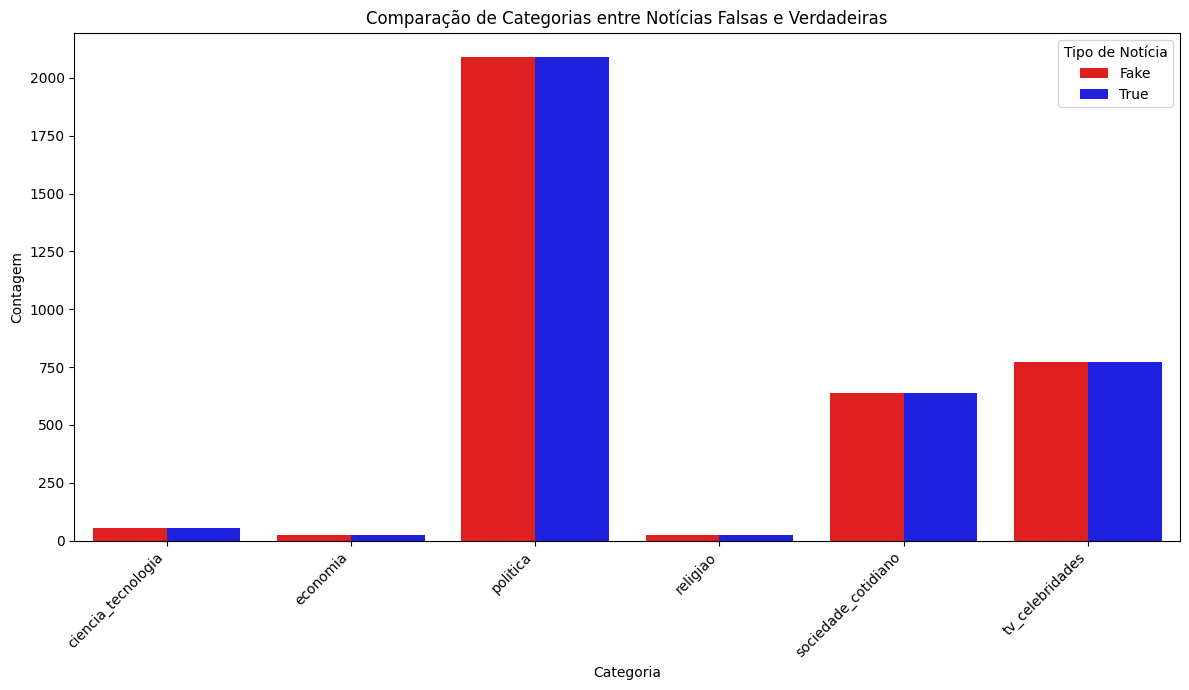

In [33]:
# Conta quantas notícias de cada categoria existem em cada classe,
# usando a coluna 'category' que já veio do merge dos metadados.
fake_category_counts = Counter(df_fake["category"].dropna())
true_category_counts = Counter(df_true["category"].dropna())
all_categories = sorted(set(df["category"].dropna()))

df_categorias = pd.DataFrame({
    "Categoria": all_categories,
    "Fake": [fake_category_counts.get(c, 0) for c in all_categories],
    "True": [true_category_counts.get(c, 0) for c in all_categories],
})
display(df_categorias)

# 'melt' transforma as colunas Fake/True em uma única coluna categórica,
# formato que o seaborn precisa para desenhar barras agrupadas por 'hue'.
df_plot = df_categorias.melt(id_vars="Categoria", var_name="Tipo de Notícia", value_name="Contagem")
plt.figure(figsize=(12, 7))
sns.barplot(x="Categoria", y="Contagem", hue="Tipo de Notícia", data=df_plot,
            palette={"Fake": "red", "True": "blue"})
plt.title("Comparação de Categorias entre Notícias Falsas e Verdadeiras")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### 2.2.1 Conclusão — categorias

In [34]:
# Categoria mais comum em cada classe, e categorias exclusivas de uma delas.
# CORREÇÃO: a coluna se chama "True", que é uma palavra reservada do Python.
# df.query("True == 0") interpretava esse "True" como o literal booleano, não
# como o nome da coluna, e quebrava com TypeError. Trocamos por indexação
# booleana normal, que não sofre desse problema.
top_fake = df_categorias.loc[df_categorias["Fake"].idxmax()]
top_true = df_categorias.loc[df_categorias["True"].idxmax()]
so_fake = df_categorias.loc[(df_categorias["Fake"] > 0) & (df_categorias["True"] == 0), "Categoria"].tolist()
so_true = df_categorias.loc[(df_categorias["True"] > 0) & (df_categorias["Fake"] == 0), "Categoria"].tolist()

print(
    f"A categoria mais frequente entre notícias falsas é '{top_fake['Categoria']}' "
    f"({top_fake['Fake']} notícias), enquanto entre as verdadeiras é '{top_true['Categoria']}' "
    f"({top_true['True']} notícias)."
)
if so_fake:
    print(f"Categorias que só aparecem entre as falsas: {', '.join(so_fake)}.")
if so_true:
    print(f"Categorias que só aparecem entre as verdadeiras: {', '.join(so_true)}.")
if not so_fake and not so_true:
    print("Todas as categorias aparecem em ambas as classes.")

A categoria mais frequente entre notícias falsas é 'politica' (2090 notícias), enquanto entre as verdadeiras é 'politica' (2090 notícias).
Todas as categorias aparecem em ambas as classes.


### 2.3 Definições de Métricas Linguísticas

Nesta seção, definimos as métricas linguísticas usadas para analisar as características dos textos:

**Emotiveness (expressividade emocional)**:
Fórmula: *(número de adjetivos + número de advérbios) / (número de substantivos + número de verbos)*

A ideia por trás dessa métrica é que adjetivos e advérbios carregam mais carga subjetiva/emocional ("terrível", "absurdamente", "chocante"), enquanto substantivos e verbos tendem a carregar mais o conteúdo factual/objetivo da frase. Quanto maior o valor, mais "carregado" emocionalmente é o texto em relação ao seu conteúdo factual.

**Diversity (diversidade lexical)**:
Geralmente calculada como type-token ratio (TTR): *número de palavras únicas (types) / número total de palavras (tokens)*.

Mede o quanto o vocabulário do texto é variado versus repetitivo.

**Pausality (Taxa de ocorrência de sinais de pontuação nas frases)**:
Essa métrica indica a frequência de pontuação (como vírgulas, pontos, etc.) no texto, podendo refletir a complexidade sintática ou o ritmo da escrita.

#### 2.3.1 Análise de Emotividade, Diversidade e Pausalidade

/tmp/ipykernel_5835/4188968189.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y=field_name, ax=ax, palette={"fake": "red", "true": "blue"})
/tmp/ipykernel_5835/4188968189.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y=field_name, ax=ax, palette={"fake": "red", "true": "blue"})
/tmp/ipykernel_5835/4188968189.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y=field_name, ax=ax, palette={"fake": "red", "true": "blue"})
/tmp/ipykernel_5835/4188968189.py:7: FutureWarning: 

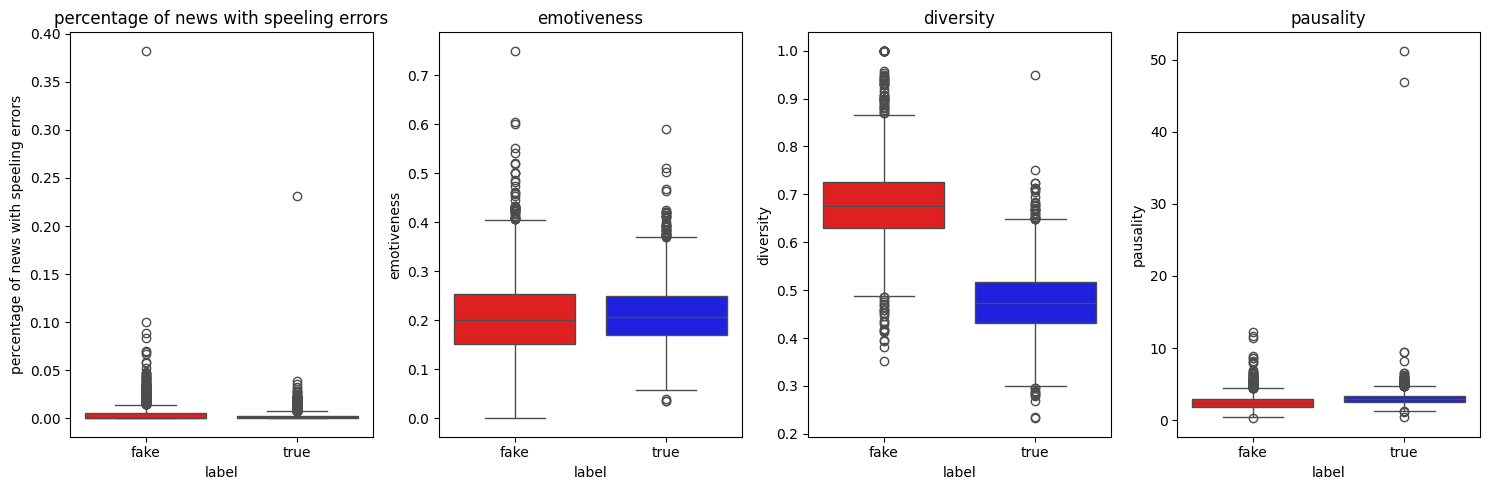

,percentage of news with speeling errors,emotiveness,diversity,pausality
label,,,,
fake,0.003859,0.205708,0.680282,2.468517
true,0.002270,0.213808,0.475524,3.042928


In [35]:
# Comparamos as distribuições completas (não só a média) com boxplots,
# um painel por métrica, para ver também a dispersão e possíveis outliers.
campos_para_analisar = ["percentage of news with speeling errors", "emotiveness", "diversity","pausality"]

fig, axes = plt.subplots(1, len(campos_para_analisar), figsize=(15, 5))
for ax, field_name in zip(axes, campos_para_analisar):
    sns.boxplot(data=df, x="label", y=field_name, ax=ax, palette={"fake": "red", "true": "blue"})
    ax.set_title(field_name)
plt.tight_layout()
plt.show()

medias = df.groupby("label")[campos_para_analisar].mean()
medias

#### 2.3.2 Conclusão — métricas linguísticas

In [36]:
# Para cada métrica, identifica qual classe tem o valor médio mais alto
# e monta uma frase de conclusão a partir disso.
for campo in campos_para_analisar:
    classe_maior = medias[campo].idxmax()
    print(
        f"Em média, notícias '{classe_maior}' têm {campo} mais alto "
        f"(fake: {medias.loc['fake', campo]:.3f} | true: {medias.loc['true', campo]:.3f})."
    )

Em média, notícias 'fake' têm percentage of news with speeling errors mais alto (fake: 0.004 | true: 0.002).
Em média, notícias 'true' têm emotiveness mais alto (fake: 0.206 | true: 0.214).
Em média, notícias 'fake' têm diversity mais alto (fake: 0.680 | true: 0.476).
Em média, notícias 'true' têm pausality mais alto (fake: 2.469 | true: 3.043).


In [37]:
# Re-exibindo a conclusão da inspeção estrutural
media_fake = df_fake["tamanho_caracteres"].mean()
media_true = df_true["tamanho_caracteres"].mean()
classe_mais_longa = "verdadeiras" if media_true > media_fake else "falsas"

duplicatas_fake = df_fake.duplicated(subset="texto").sum()
duplicatas_true = df_true.duplicated(subset="texto").sum()
curtas_fake = (df_fake["tamanho_caracteres"] < 50).sum()
curtas_true = (df_true["tamanho_caracteres"] < 50).sum()

print(
    f"As notícias {classe_mais_longa} são, em média, mais longas "
    f"({media_true:.0f} caracteres em 'true' vs. {media_fake:.0f} em 'fake'). "
    f"Foram encontradas {duplicatas_fake} duplicatas em 'fake' e {duplicatas_true} em 'true', "
    f"além de {curtas_fake} notícias 'fake' e {curtas_true} notícias 'true' com menos de "
    "50 caracteres — candidatas a erro de coleta e que merecem checagem manual antes de "
    "qualquer treino de modelo."
)

As notícias verdadeiras são, em média, mais longas (6674 caracteres em 'true' vs. 1124 em 'fake'). Foram encontradas 0 duplicatas em 'fake' e 1 em 'true', além de 1 notícias 'fake' e 0 notícias 'true' com menos de 50 caracteres — candidatas a erro de coleta e que merecem checagem manual antes de qualquer treino de modelo.


,Categoria,Fake,True
0,ciencia_tecnologia,56,56
1,economia,22,22
2,politica,2090,2090
3,religiao,22,22
4,sociedade_cotidiano,638,638
5,tv_celebridades,772,772


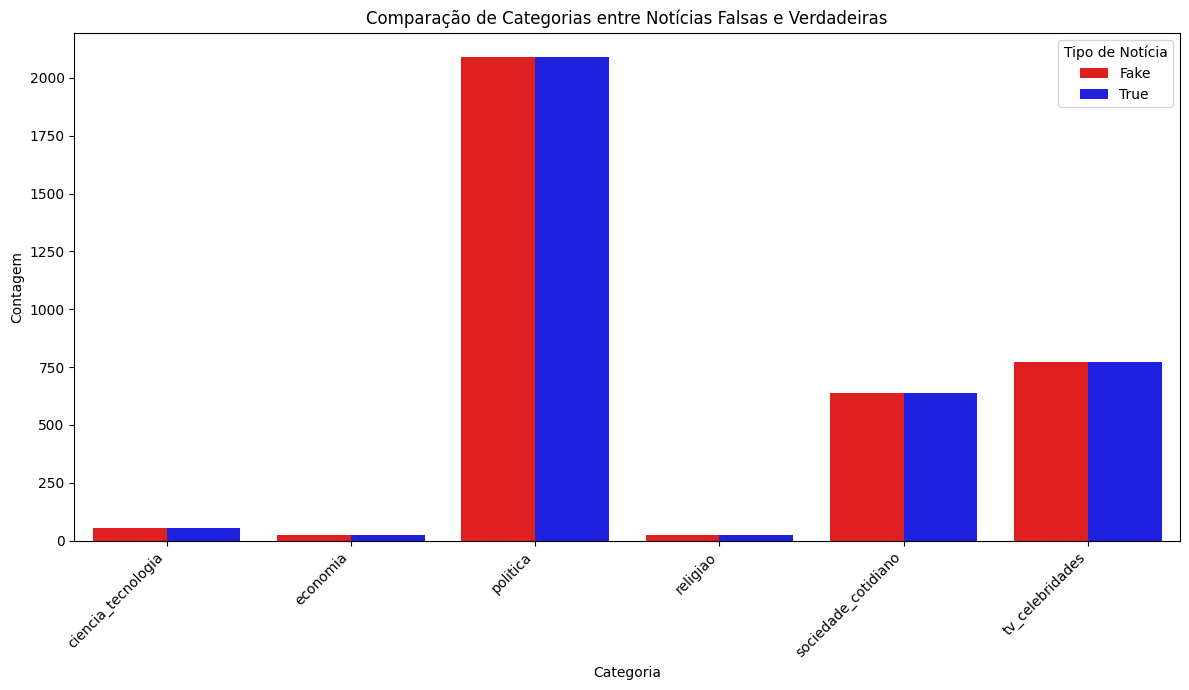

In [38]:
# Re-exibindo a tabela de categorias
display(df_categorias)

# Re-exibindo o gráfico de categorias
plt.figure(figsize=(12, 7))
sns.barplot(x="Categoria", y="Contagem", hue="Tipo de Notícia", data=df_plot,
            palette={"Fake": "red", "True": "blue"})
plt.title("Comparação de Categorias entre Notícias Falsas e Verdadeiras")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [39]:
# Re-exibindo a conclusão das categorias
top_fake = df_categorias.loc[df_categorias["Fake"].idxmax()]
top_true = df_categorias.loc[df_categorias["True"].idxmax()]
so_fake = df_categorias.loc[(df_categorias["Fake"] > 0) & (df_categorias["True"] == 0), "Categoria"].tolist()
so_true = df_categorias.loc[(df_categorias["True"] > 0) & (df_categorias["Fake"] == 0), "Categoria"].tolist()

print(
    f"A categoria mais frequente entre notícias falsas é '{top_fake['Categoria']}' "
    f"({top_fake['Fake']} notícias), enquanto entre as verdadeiras é '{top_true['Categoria']}' "
    f"({top_true['True']} notícias)."
)
if so_fake:
    print(f"Categorias que só aparecem entre as falsas: {', '.join(so_fake)}.")
if so_true:
    print(f"Categorias que só aparecem entre as verdadeiras: {', '.join(so_true)}.")
if not so_fake and not so_true:
    print("Todas as categorias aparecem em ambas as classes.")

A categoria mais frequente entre notícias falsas é 'politica' (2090 notícias), enquanto entre as verdadeiras é 'politica' (2090 notícias).
Todas as categorias aparecem em ambas as classes.


/tmp/ipykernel_5835/3586917689.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y=field_name, ax=ax, palette={"fake": "red", "true": "blue"})
/tmp/ipykernel_5835/3586917689.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y=field_name, ax=ax, palette={"fake": "red", "true": "blue"})
/tmp/ipykernel_5835/3586917689.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y=field_name, ax=ax, palette={"fake": "red", "true": "blue"})
/tmp/ipykernel_5835/3586917689.py:4: FutureWarning: 

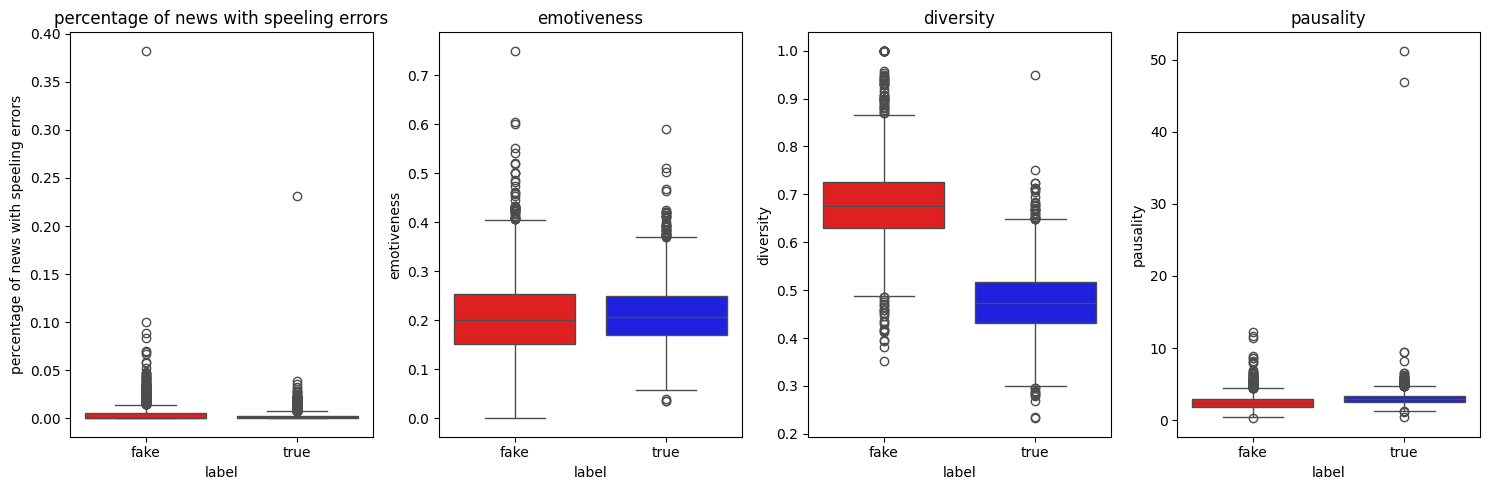

In [40]:
# Re-exibindo os boxplots
fig, axes = plt.subplots(1, len(campos_para_analisar), figsize=(15, 5))
for ax, field_name in zip(axes, campos_para_analisar):
    sns.boxplot(data=df, x="label", y=field_name, ax=ax, palette={"fake": "red", "true": "blue"})
    ax.set_title(field_name)
plt.tight_layout()
plt.show()

In [41]:
# Re-exibindo a tabela de médias
display(medias)

,percentage of news with speeling errors,emotiveness,diversity,pausality
label,,,,
fake,0.003859,0.205708,0.680282,2.468517
true,0.002270,0.213808,0.475524,3.042928


In [42]:
# Re-exibindo a conclusão das características linguísticas
for campo in campos_para_analisar:
    classe_maior = medias[campo].idxmax()
    print(
        f"Em média, notícias '{classe_maior}' têm {campo} mais alto "
        f"(fake: {medias.loc['fake', campo]:.3f} | true: {medias.loc['true', campo]:.3f})."
    )

Em média, notícias 'fake' têm percentage of news with speeling errors mais alto (fake: 0.004 | true: 0.002).
Em média, notícias 'true' têm emotiveness mais alto (fake: 0.206 | true: 0.214).
Em média, notícias 'fake' têm diversity mais alto (fake: 0.680 | true: 0.476).
Em média, notícias 'true' têm pausality mais alto (fake: 2.469 | true: 3.043).


In [43]:
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Médias das principais características disponíveis
# ------------------------------------------------------------

# Agrupa os dados por classe
estatisticas = df.groupby("label").agg({
    "number of tokens": "mean",
    "number of types": "mean",
    "average word length": "mean",
    "diversity": "mean",
    "average sentence length": "mean",
    "number of verbs": "mean",
    "number of nouns": "mean",
    "number of adjectives": "mean",
    "number of adverbs": "mean",
    "number of pronouns": "mean"
})

# ------------------------------------------------------------
# 2. Normalização das classes
# ------------------------------------------------------------

# Criamos as colunas na ordem desejada:
# True news | Fake news

tabela_basica = pd.DataFrame(index=[
    "Average number of tokens",
    "Average number of types (without punctuation symbols and numbers)",
    "Average size of words (in characters)",
    "Type-token ratio",
    "Average number of sentences",
    "Average size of sentences (in words)",
    "Average number of verbs (normalized by tokens)",
    "Average number of nouns (normalized by tokens)",
    "Average number of adjectives (normalized by tokens)",
    "Average number of adverbs (normalized by tokens)",
    "Average number of pronouns (normalized by tokens)",
    "Percentage of texts with spelling errors"
])

# ------------------------------------------------------------
# 3. Características diretamente disponíveis no metadata
# ------------------------------------------------------------

tabela_basica.loc[
    "Average number of tokens", "True news"
] = estatisticas.loc["true", "number of tokens"]

tabela_basica.loc[
    "Average number of tokens", "Fake news"
] = estatisticas.loc["fake", "number of tokens"]


tabela_basica.loc[
    "Average number of types (without punctuation symbols and numbers)",
    "True news"
] = estatisticas.loc["true", "number of types"]

tabela_basica.loc[
    "Average number of types (without punctuation symbols and numbers)",
    "Fake news"
] = estatisticas.loc["fake", "number of types"]


tabela_basica.loc[
    "Average size of words (in characters)", "True news"
] = estatisticas.loc["true", "average word length"]

tabela_basica.loc[
    "Average size of words (in characters)", "Fake news"
] = estatisticas.loc["fake", "average word length"]


# ------------------------------------------------------------
# 4. Type-token ratio
# ------------------------------------------------------------

tabela_basica.loc[
    "Type-token ratio", "True news"
] = estatisticas.loc["true", "diversity"]

tabela_basica.loc[
    "Type-token ratio", "Fake news"
] = estatisticas.loc["fake", "diversity"]


# ------------------------------------------------------------
# 5. Tamanho médio das sentenças
# ------------------------------------------------------------

tabela_basica.loc[
    "Average size of sentences (in words)", "True news"
] = estatisticas.loc["true", "average sentence length"]

tabela_basica.loc[
    "Average size of sentences (in words)", "Fake news"
] = estatisticas.loc["fake", "average sentence length"]


# ------------------------------------------------------------
# 6. Número médio de sentenças
# ------------------------------------------------------------
#
# O metadata original não possui uma coluna explícita
# "number of sentences".
#
# Portanto, NÃO vamos inventar esse valor.
# Neste momento, deixamos como NaN e explicamos abaixo.
#

tabela_basica.loc[
    "Average number of sentences", "True news"
] = np.nan

tabela_basica.loc[
    "Average number of sentences", "Fake news"
] = np.nan


# ------------------------------------------------------------
# 7. POS tags normalizadas pelo número de tokens
# ------------------------------------------------------------
#
# O artigo apresenta essas medidas como valores normalizados.
# Multiplicamos por 100 para obter uma porcentagem dos tokens.
#

pos_columns = {
    "Average number of verbs (normalized by tokens)": "number of verbs",
    "Average number of nouns (normalized by tokens)": "number of nouns",
    "Average number of adjectives (normalized by tokens)": "number of adjectives",
    "Average number of adverbs (normalized by tokens)": "number of adverbs",
    "Average number of pronouns (normalized by tokens)": "number of pronouns"
}

for nome_tabela, coluna_df in pos_columns.items():

    tabela_basica.loc[nome_tabela, "True news"] = (
        estatisticas.loc["true", coluna_df]
        / estatisticas.loc["true", "number of tokens"]
        * 100
    )

    tabela_basica.loc[nome_tabela, "Fake news"] = (
        estatisticas.loc["fake", coluna_df]
        / estatisticas.loc["fake", "number of tokens"]
        * 100
    )


# ------------------------------------------------------------
# 8. Proporção de textos com erros ortográficos
# ------------------------------------------------------------
#
# A variável "percentage of news with speeling errors"
# representa a proporção de erros por notícia.
#
# Para reproduzir a ideia da tabela do artigo, consideramos
# que uma notícia possui erro quando o valor é maior que zero.
#

erros_fake = (
    (df.loc[df["label"] == "fake",
           "percentage of news with speeling errors"] > 0)
    .mean() * 100
)

erros_true = (
    (df.loc[df["label"] == "true",
           "percentage of news with speeling errors"] > 0)
    .mean() * 100
)

tabela_basica.loc[
    "Percentage of texts with spelling errors", "True news"
] = erros_true

tabela_basica.loc[
    "Percentage of texts with spelling errors", "Fake news"
] = erros_fake


# ------------------------------------------------------------
# 9. Formatação
# ------------------------------------------------------------

tabela_basica = tabela_basica.astype(float)

display(
    tabela_basica.style
    .format("{:.2f}", na_rep="—")
    .set_caption("Basic analysis of the Fake.Br Corpus.")
)

,True news,Fake news
Average number of tokens,1269.29,216.24
Average number of types (without punctuation symbols and numbers),494.43,119.36
Average size of words (in characters),4.87,4.82
Type-token ratio,0.48,0.68
Average number of sentences,—,—
Average size of sentences (in words),21.15,15.31
Average number of verbs (normalized by tokens),13.42,14.43
Average number of nouns (normalized by tokens),24.61,24.73
Average number of adjectives (normalized by tokens),4.49,4.28
Average number of adverbs (normalized by tokens),4.04,4.03


## 3. Relatório Completo da Análise Exploratória de Dados

In [44]:
# Re-exibindo a conclusão da inspeção estrutural
media_fake = df_fake["tamanho_caracteres"].mean()
media_true = df_true["tamanho_caracteres"].mean()
classe_mais_longa = "verdadeiras" if media_true > media_fake else "falsas"

duplicatas_fake = df_fake.duplicated(subset="texto").sum()
duplicatas_true = df_true.duplicated(subset="texto").sum()
curtas_fake = (df_fake["tamanho_caracteres"] < 50).sum()
curtas_true = (df_true["tamanho_caracteres"] < 50).sum()

print(
    f"As notícias {classe_mais_longa} são, em média, mais longas "
    f"({media_true:.0f} caracteres em 'true' vs. {media_fake:.0f} em 'fake'). "
    f"Foram encontradas {duplicatas_fake} duplicatas em 'fake' e {duplicatas_true} em 'true', "
    f"além de {curtas_fake} notícias 'fake' e {curtas_true} notícias 'true' com menos de "
    "50 caracteres — candidatas a erro de coleta e que merecem checagem manual antes de "
    "qualquer treino de modelo."
)

As notícias verdadeiras são, em média, mais longas (6674 caracteres em 'true' vs. 1124 em 'fake'). Foram encontradas 0 duplicatas em 'fake' e 1 em 'true', além de 1 notícias 'fake' e 0 notícias 'true' com menos de 50 caracteres — candidatas a erro de coleta e que merecem checagem manual antes de qualquer treino de modelo.


,Categoria,Fake,True
0,ciencia_tecnologia,56,56
1,economia,22,22
2,politica,2090,2090
3,religiao,22,22
4,sociedade_cotidiano,638,638
5,tv_celebridades,772,772


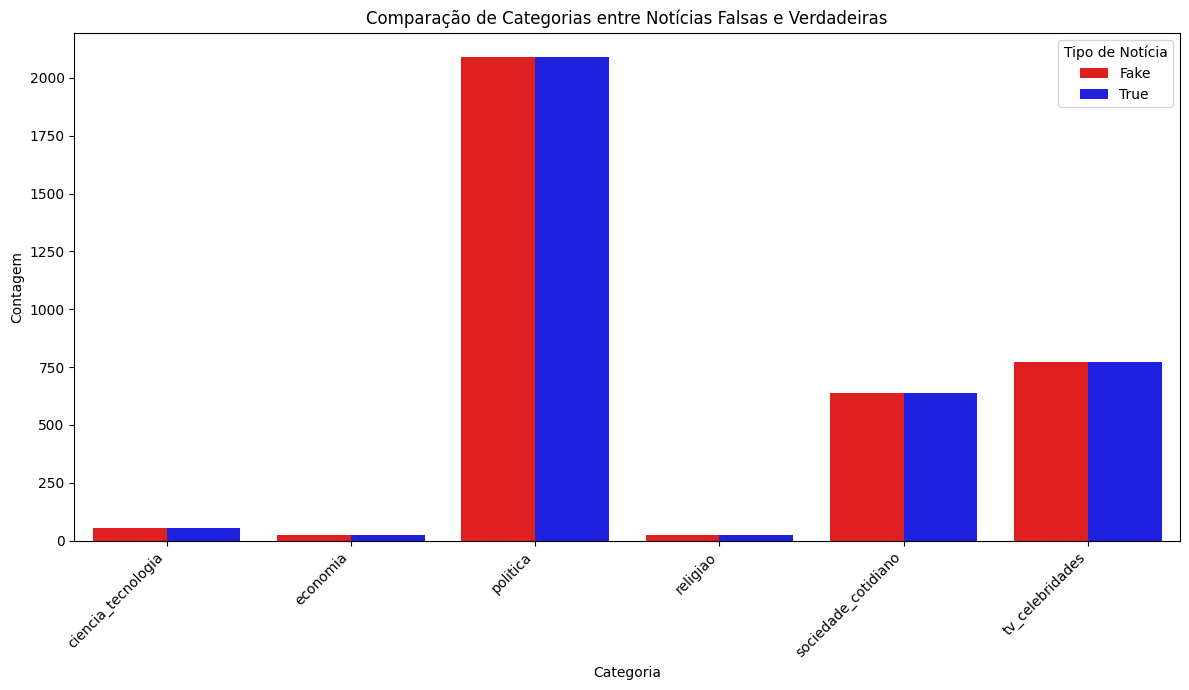

In [45]:
# Re-exibindo a tabela de categorias
display(df_categorias)

# Re-exibindo o gráfico de categorias
plt.figure(figsize=(12, 7))
sns.barplot(x="Categoria", y="Contagem", hue="Tipo de Notícia", data=df_plot,
            palette={"Fake": "red", "True": "blue"})
plt.title("Comparação de Categorias entre Notícias Falsas e Verdadeiras")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [46]:
# Re-exibindo a conclusão das categorias
top_fake = df_categorias.loc[df_categorias["Fake"].idxmax()]
top_true = df_categorias.loc[df_categorias["True"].idxmax()]
so_fake = df_categorias.loc[(df_categorias["Fake"] > 0) & (df_categorias["True"] == 0), "Categoria"].tolist()
so_true = df_categorias.loc[(df_categorias["True"] > 0) & (df_categorias["Fake"] == 0), "Categoria"].tolist()

print(
    f"A categoria mais frequente entre notícias falsas é '{top_fake['Categoria']}' "
    f"({top_fake['Fake']} notícias), enquanto entre as verdadeiras é '{top_true['Categoria']}' "
    f"({top_true['True']} notícias)."
)
if so_fake:
    print(f"Categorias que só aparecem entre as falsas: {', '.join(so_fake)}.")
if so_true:
    print(f"Categorias que só aparecem entre as verdadeiras: {', '.join(so_true)}.")
if not so_fake and not so_true:
    print("Todas as categorias aparecem em ambas as classes.")

A categoria mais frequente entre notícias falsas é 'politica' (2090 notícias), enquanto entre as verdadeiras é 'politica' (2090 notícias).
Todas as categorias aparecem em ambas as classes.


/tmp/ipykernel_5835/3586917689.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y=field_name, ax=ax, palette={"fake": "red", "true": "blue"})
/tmp/ipykernel_5835/3586917689.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y=field_name, ax=ax, palette={"fake": "red", "true": "blue"})
/tmp/ipykernel_5835/3586917689.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y=field_name, ax=ax, palette={"fake": "red", "true": "blue"})
/tmp/ipykernel_5835/3586917689.py:4: FutureWarning: 

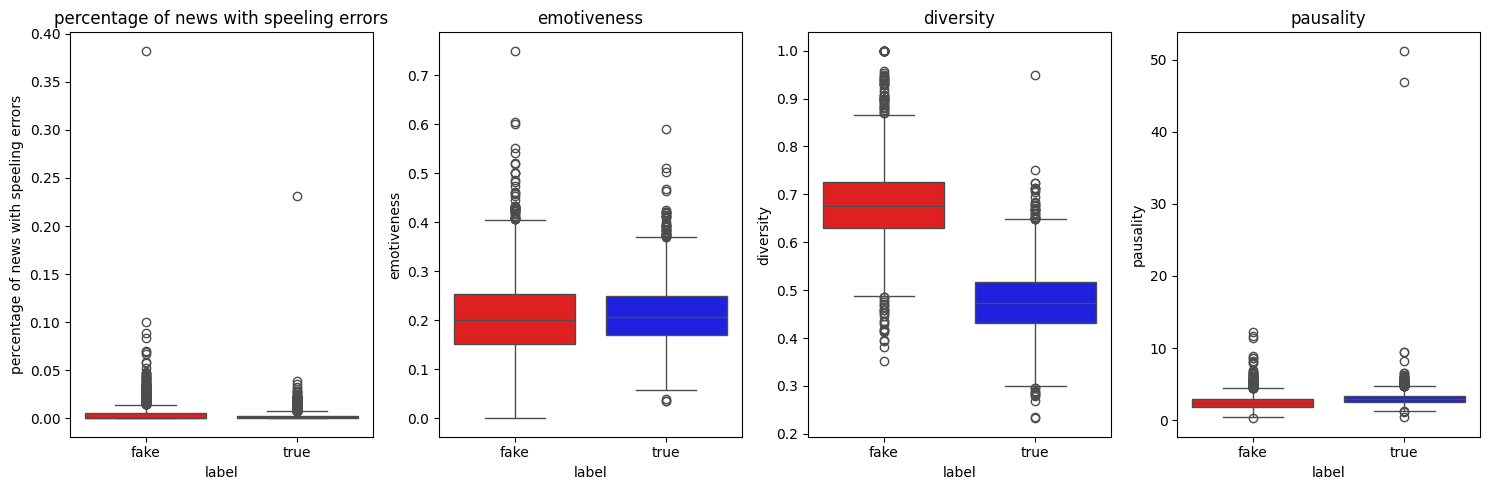

In [47]:
# Re-exibindo os boxplots
fig, axes = plt.subplots(1, len(campos_para_analisar), figsize=(15, 5))
for ax, field_name in zip(axes, campos_para_analisar):
    sns.boxplot(data=df, x="label", y=field_name, ax=ax, palette={"fake": "red", "true": "blue"})
    ax.set_title(field_name)
plt.tight_layout()
plt.show()

In [48]:
# Re-exibindo a tabela de médias
display(medias)

,percentage of news with speeling errors,emotiveness,diversity,pausality
label,,,,
fake,0.003859,0.205708,0.680282,2.468517
true,0.002270,0.213808,0.475524,3.042928


In [49]:
# Re-exibindo a conclusão das características linguísticas
for campo in campos_para_analisar:
    classe_maior = medias[campo].idxmax()
    print(
        f"Em média, notícias '{classe_maior}' têm {campo} mais alto "
        f"(fake: {medias.loc['fake', campo]:.3f} | true: {medias.loc['true', campo]:.3f})."
    )

Em média, notícias 'fake' têm percentage of news with speeling errors mais alto (fake: 0.004 | true: 0.002).
Em média, notícias 'true' têm emotiveness mais alto (fake: 0.206 | true: 0.214).
Em média, notícias 'fake' têm diversity mais alto (fake: 0.680 | true: 0.476).
Em média, notícias 'true' têm pausality mais alto (fake: 2.469 | true: 3.043).


In [50]:
# Re-exibindo a tabela de análise básica
display(
    tabela_basica.style
    .format("{:.2f}", na_rep="—")
    .set_caption("Basic analysis of the Fake.Br Corpus.")
)

,True news,Fake news
Average number of tokens,1269.29,216.24
Average number of types (without punctuation symbols and numbers),494.43,119.36
Average size of words (in characters),4.87,4.82
Type-token ratio,0.48,0.68
Average number of sentences,—,—
Average size of sentences (in words),21.15,15.31
Average number of verbs (normalized by tokens),13.42,14.43
Average number of nouns (normalized by tokens),24.61,24.73
Average number of adjectives (normalized by tokens),4.49,4.28
Average number of adverbs (normalized by tokens),4.04,4.03


In [51]:
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Médias das principais características disponíveis
# ------------------------------------------------------------

# Agrupa os dados por classe
estatisticas = df.groupby("label").agg({
    "number of tokens": "mean",
    "number of types": "mean",
    "average word length": "mean",
    "diversity": "mean",
    "average sentence length": "mean",
    "number of verbs": "mean",
    "number of nouns": "mean",
    "number of adjectives": "mean",
    "number of adverbs": "mean",
    "number of pronouns": "mean"
})

# ------------------------------------------------------------
# 2. Normalização das classes
# ------------------------------------------------------------

# Criamos as colunas na ordem desejada:
# True news | Fake news

tabela_basica = pd.DataFrame(index=[
    "Average number of tokens",
    "Average number of types (without punctuation symbols and numbers)",
    "Average size of words (in characters)",
    "Type-token ratio",
    "Average number of sentences",
    "Average size of sentences (in words)",
    "Average number of verbs (normalized by tokens)",
    "Average number of nouns (normalized by tokens)",
    "Average number of adjectives (normalized by tokens)",
    "Average number of adverbs (normalized by tokens)",
    "Average number of pronouns (normalized by tokens)",
    "Percentage of texts with spelling errors"
])

# ------------------------------------------------------------
# 3. Características diretamente disponíveis no metadata
# ------------------------------------------------------------

tabela_basica.loc[
    "Average number of tokens", "True news"
] = estatisticas.loc["true", "number of tokens"]

tabela_basica.loc[
    "Average number of tokens", "Fake news"
] = estatisticas.loc["fake", "number of tokens"]


tabela_basica.loc[
    "Average number of types (without punctuation symbols and numbers)",
    "True news"
] = estatisticas.loc["true", "number of types"]

tabela_basica.loc[
    "Average number of types (without punctuation symbols and numbers)",
    "Fake news"
] = estatisticas.loc["fake", "number of types"]


tabela_basica.loc[
    "Average size of words (in characters)", "True news"
] = estatisticas.loc["true", "average word length"]

tabela_basica.loc[
    "Average size of words (in characters)", "Fake news"
] = estatisticas.loc["fake", "average word length"]


# ------------------------------------------------------------
# 4. Type-token ratio
# ------------------------------------------------------------

tabela_basica.loc[
    "Type-token ratio", "True news"
] = estatisticas.loc["true", "diversity"]

tabela_basica.loc[
    "Type-token ratio", "Fake news"
] = estatisticas.loc["fake", "diversity"]


# ------------------------------------------------------------
# 5. Tamanho médio das sentenças
# ------------------------------------------------------------

tabela_basica.loc[
    "Average size of sentences (in words)", "True news"
] = estatisticas.loc["true", "average sentence length"]

tabela_basica.loc[
    "Average size of sentences (in words)", "Fake news"
] = estatisticas.loc["fake", "average sentence length"]


# ------------------------------------------------------------
# 6. Número médio de sentenças
# ------------------------------------------------------------
#
# O metadata original não possui uma coluna explícita
# "number of sentences".
#
# Portanto, NÃO vamos inventar esse valor.
# Neste momento, deixamos como NaN e explicamos abaixo.
#

tabela_basica.loc[
    "Average number of sentences", "True news"
] = np.nan

tabela_basica.loc[
    "Average number of sentences", "Fake news"
] = np.nan


# ------------------------------------------------------------
# 7. POS tags normalizadas pelo número de tokens
# ------------------------------------------------------------
#
# O artigo apresenta essas medidas como valores normalizados.
# Multiplicamos por 100 para obter uma porcentagem dos tokens.
#

pos_columns = {
    "Average number of verbs (normalized by tokens)": "number of verbs",
    "Average number of nouns (normalized by tokens)": "number of nouns",
    "Average number of adjectives (normalized by tokens)": "number of adjectives",
    "Average number of adverbs (normalized by tokens)": "number of adverbs",
    "Average number of pronouns (normalized by tokens)": "number of pronouns"
}

for nome_tabela, coluna_df in pos_columns.items():

    tabela_basica.loc[nome_tabela, "True news"] = (
        estatisticas.loc["true", coluna_df]
        / estatisticas.loc["true", "number of tokens"]
        * 100
    )

    tabela_basica.loc[nome_tabela, "Fake news"] = (
        estatisticas.loc["fake", coluna_df]
        / estatisticas.loc["fake", "number of tokens"]
        * 100
    )


# ------------------------------------------------------------
# 8. Proporção de textos com erros ortográficos
# ------------------------------------------------------------
#
# A variável "percentage of news with speeling errors"
# representa a proporção de erros por notícia.
#
# Para reproduzir a ideia da tabela do artigo, consideramos
# que uma notícia possui erro quando o valor é maior que zero.
#

erros_fake = (
    (df.loc[df["label"] == "fake",
           "percentage of news with speeling errors"] > 0)
    .mean() * 100
)

erros_true = (
    (df.loc[df["label"] == "true",
           "percentage of news with speeling errors"] > 0)
    .mean() * 100
)

tabela_basica.loc[
    "Percentage of texts with spelling errors", "True news"
] = erros_true

tabela_basica.loc[
    "Percentage of texts with spelling errors", "Fake news"
] = erros_fake


# ------------------------------------------------------------
# 9. Formatação
# ------------------------------------------------------------

tabela_basica = tabela_basica.astype(float)

display(
    tabela_basica.style
    .format("{:.2f}", na_rep="—")
    .set_caption("Basic analysis of the Fake.Br Corpus.")
)

,True news,Fake news
Average number of tokens,1269.29,216.24
Average number of types (without punctuation symbols and numbers),494.43,119.36
Average size of words (in characters),4.87,4.82
Type-token ratio,0.48,0.68
Average number of sentences,—,—
Average size of sentences (in words),21.15,15.31
Average number of verbs (normalized by tokens),13.42,14.43
Average number of nouns (normalized by tokens),24.61,24.73
Average number of adjectives (normalized by tokens),4.49,4.28
Average number of adverbs (normalized by tokens),4.04,4.03
